# Project 1: Text classification on SST-2
We compare systems made of a text representation (encoder) and a classifier, using
cross-validation accuracy and Bayesian analysis with a ROPE. Current grid: 2 encoders
(token indicators, bag of words) x 2 models (log-linear, single-hidden-layer MLP).
The grid is designed to grow: new systems are added by one `run_system(...)` call.

## Setup
Imports and working directory. Run these cells every session.

In [1]:
import os, pickle
import pandas as pd
from collections import OrderedDict, Counter
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

#if '/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1' == os.getcwd():
if os.path.basename(os.getcwd()) == "Project1":
    os.chdir("..")
print(os.getcwd())

import Project1.experiment as experiment
import Project1.clslib as clslib
import Project1.analysis as analysis
import Project1.loglin as loglin
import Project1.smlp as smlp

C:\My documents\UvA\NLP\Projects\Project_1\git\NLP


### Storing results
Helpers to save each system's cross-validation results (one `.pkl` per system) and
load them back, so analysis never requires retraining.

In [2]:
RESULTS_STORE = "Project1/results/stored_results"
os.makedirs(RESULTS_STORE, exist_ok=True)

def save_system(name):
    with open(f"{RESULTS_STORE}/{name}.pkl", "wb") as f:
        pickle.dump(my_classifiers[name], f)

def load_all_systems():
    loaded = OrderedDict()
    for fname in sorted(os.listdir(RESULTS_STORE)):
        if fname.endswith(".pkl"):
            with open(f"{RESULTS_STORE}/{fname}", "rb") as f:
                loaded[fname[:-4]] = pickle.load(f)
    return loaded

## Data
SST-2: sentences labelled negative (0) or positive (1). We use the train split for
cross-validation; the official test labels are hidden.

In [3]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/sst2")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 872
    })
    test: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 1821
    })
})


## Data exploration

SST-2 contains movie-review text labelled negative (0) or positive (1). The train split
consists of full sentences plus many short phrases extracted from the same sentences, while
validation and test hold full sentences. The official test labels are hidden (-1), so the test
split cannot be used for scoring. This section shows examples, the label distribution, and
text length statistics for each split.

In [4]:
stanfordnlpsst2_outcome_space = clslib.NamedClasses(['negative', 'positive'])
names = stanfordnlpsst2_outcome_space.names   # ('negative', 'positive')

print(f"--- train: {len(dataset['train'])} instances, first 5 ---")
for ex in dataset["train"].select(range(5)):
    print(f"[{names[ex['label']]}] {ex['sentence'].strip()}")

--- train: 67349 instances, first 5 ---
[negative] hide new secretions from the parental units
[negative] contains no wit , only labored gags
[positive] that loves its characters and communicates something rather beautiful about human nature
[negative] remains utterly satisfied to remain the same throughout
[negative] on the worst revenge-of-the-nerds clichés the filmmakers could dredge up


,label,count,share
0,negative,29780,0.442
1,positive,37569,0.558


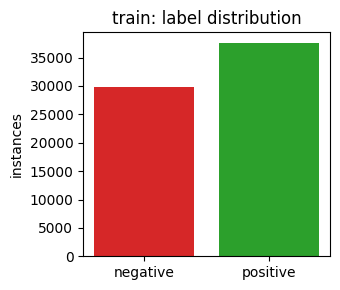

In [5]:
counts = Counter(dataset["train"]["label"])
total = sum(counts.values())

label_table = pd.DataFrame(
    [{"label": names[l], "count": n, "share": round(n / total, 3)}
     for l, n in sorted(counts.items())]
)
display(label_table)

plt.figure(figsize=(3.5, 3))
plt.bar(names, [counts[0], counts[1]], color=["tab:red", "tab:green"])
plt.ylabel("instances")
plt.title("train: label distribution")
plt.tight_layout()
plt.show()

### Tokenizer
Load our BPE tokenizer (8,000 merges) used by all encoders.

In [6]:
from tokenizers import Tokenizer

tokenizer = Tokenizer.from_file(
    f"Project1/results/bpe_8000.json"
)

output = tokenizer.encode(dataset['train']['sentence'][0])

print(output.tokens)

['h', 'ide', '▁new', '▁secret', 'ions', '▁from', '▁the', '▁parent', 'al', '▁un', 'its', '▁']


In [7]:
sents = dataset["train"]["sentence"]
n_words = np.array([len(s.split()) for s in sents])
n_tokens = np.array([len(tokenizer.encode(s).ids) for s in sents])

length_stats = pd.DataFrame({
    "mean":   [n_words.mean(), n_tokens.mean()],
    "median": [np.median(n_words), np.median(n_tokens)],
    "max":    [n_words.max(), n_tokens.max()],
}, index=["words", "BPE tokens"]).round(1)
display(length_stats)

,mean,median,max
words,9.4,7.0,52
BPE tokens,13.9,10.0,86


### Cross-validation folds
Same seeds and folds for every system, so comparisons are fair. Changing these
requires retraining all systems.

In [8]:
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["sentence"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

## Representation spaces (encoders)
- **Token indicator:** 1 if a token occurs in the text, else 0.
- **Bag of words:** how many times each token occurs.
Both ignore word order.

In [9]:
class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the documentBelow the token Bag of Words feature representation space.
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [10]:
class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a vector of token counts"""
        unique_token_ids = self.tokenizer.encode(x).ids
        
        # A 0 vector with the same length as the vocabulary, then one count per occurrence
        vector = np.zeros(len(self))
        for token_id in unique_token_ids:
            vector[token_id] += 1
        return vector

Create the label space and one instance of each encoder.

In [11]:
token_indicator_encoder = TokenIndicator(tokenizer)
bag_of_words_encoder = BagOfWords(tokenizer)

## Load saved results
Restore all stored systems from disk. No training happens here.

In [12]:
my_classifiers = load_all_systems()   # restores the systems from the .pkl files
print(list(my_classifiers.keys()))

['logistic_bow-enc', 'logistic_indicator-enc', 'mlp_bow-enc', 'mlp_indicator-enc']


## Training
`run_system` runs cross-validation for one system and saves its results automatically.
**The cells below are slow (about 3 minutes for log-linear, 20+ for MLP). Run them only
to retrain or add a system; they overwrite saved models.**

In [13]:
def run_system(name, encoder, model_option, **model_args):
    my_classifiers[name] = []
    for run, seed in enumerate(my_seeds):
        my_classifiers[name].append(
            experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=stanfordnlpsst2_outcome_space,
                encoder=encoder, model_option=model_option,
                save_to=f"Project1/results/{name}/seed-{seed}",
                **model_args))
    save_system(name)

### Log-linear + token indicators

In [22]:
run_system('logistic_indicator-enc', token_indicator_encoder, 'logistic',
           loglin_args={'max_iter': 100})

  0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\U

### MLP + token indicators

In [23]:
run_system('mlp_indicator-enc', token_indicator_encoder, 'mlp',
           smlp_args={'hidden_dim': 128, 'dropout': 0.1, 'batch_size': 64,
                      'learning_rate': 1e-4, 'weight_decay': 1e-4, 'num_epochs': 10})

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 192.603 seconds
Dataloader done! Time taken: 16.970 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6000 | train acc: 0.6788 | val loss: 0.4797 | val acc: 0.7887
Epoch 02 | train loss: 0.4027 | train acc: 0.8426 | val loss: 0.3655 | val acc: 0.8506
Epoch 03 | train loss: 0.3220 | train acc: 0.8739 | val loss: 0.3230 | val acc: 0.8662
Epoch 04 | train loss: 0.2824 | train acc: 0.8871 | val loss: 0.3039 | val acc: 0.8724
Epoch 05 | train loss: 0.2582 | train acc: 0.8959 | val loss: 0.2919 | val acc: 0.8780
Epoch 06 | train loss: 0.2411 | train acc: 0.9032 | val loss: 0.2867 | val acc: 0.8804
Epoch 07 | train loss: 0.2276 | train acc: 0.9075 | val loss: 0.2822 | val acc: 0.8837
Epoch 08 | train loss: 0.2166 | train acc: 0.9126 | val loss: 0.2810 | val acc: 0.8867
Epoch 09 | train loss: 0.2068 | train acc: 0.9164 | val loss: 0.2803 | val acc: 0.8866
Epoch 10 | train loss: 0.1977 | train acc: 0.9198 | val loss: 0.2795 | val acc: 0.8898
Training done! Time taken: 105.335 seconds
Transforming documents...
Document transformation done! Time taken: 198.347 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6049 | train acc: 0.6751 | val loss: 0.4862 | val acc: 0.7938
Epoch 02 | train loss: 0.4020 | train acc: 0.8445 | val loss: 0.3750 | val acc: 0.8445
Epoch 03 | train loss: 0.3200 | train acc: 0.8773 | val loss: 0.3356 | val acc: 0.8555
Epoch 04 | train loss: 0.2802 | train acc: 0.8904 | val loss: 0.3179 | val acc: 0.8621
Epoch 05 | train loss: 0.2555 | train acc: 0.8991 | val loss: 0.3080 | val acc: 0.8682
Epoch 06 | train loss: 0.2386 | train acc: 0.9053 | val loss: 0.3021 | val acc: 0.8707
Epoch 07 | train loss: 0.2242 | train acc: 0.9113 | val loss: 0.2990 | val acc: 0.8729
Epoch 08 | train loss: 0.2131 | train acc: 0.9155 | val loss: 0.2975 | val acc: 0.8748
Epoch 09 | train loss: 0.2033 | train acc: 0.9193 | val loss: 0.2981 | val acc: 0.8751
Epoch 10 | train loss: 0.1939 | train acc: 0.9226 | val loss: 0.2977 | val acc: 0.8771
Training done! Time taken: 105.022 seconds
Transforming documents...
Document transformation done! Time taken: 207.363 seconds
Dat

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6011 | train acc: 0.6743 | val loss: 0.4803 | val acc: 0.8042
Epoch 02 | train loss: 0.3990 | train acc: 0.8448 | val loss: 0.3757 | val acc: 0.8520
Epoch 03 | train loss: 0.3173 | train acc: 0.8770 | val loss: 0.3396 | val acc: 0.8610
Epoch 04 | train loss: 0.2775 | train acc: 0.8899 | val loss: 0.3238 | val acc: 0.8674
Epoch 05 | train loss: 0.2523 | train acc: 0.8992 | val loss: 0.3152 | val acc: 0.8697
Epoch 06 | train loss: 0.2348 | train acc: 0.9057 | val loss: 0.3113 | val acc: 0.8715
Epoch 07 | train loss: 0.2213 | train acc: 0.9107 | val loss: 0.3086 | val acc: 0.8748
Epoch 08 | train loss: 0.2096 | train acc: 0.9157 | val loss: 0.3081 | val acc: 0.8765
Epoch 09 | train loss: 0.2001 | train acc: 0.9205 | val loss: 0.3073 | val acc: 0.8800
Epoch 10 | train loss: 0.1918 | train acc: 0.9236 | val loss: 0.3082 | val acc: 0.8804
Training done! Time taken: 111.365 seconds
Transforming documents...
Document transformation done! Time taken: 210.526 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6022 | train acc: 0.6834 | val loss: 0.4829 | val acc: 0.8060
Epoch 02 | train loss: 0.4025 | train acc: 0.8448 | val loss: 0.3702 | val acc: 0.8500
Epoch 03 | train loss: 0.3203 | train acc: 0.8759 | val loss: 0.3301 | val acc: 0.8624
Epoch 04 | train loss: 0.2810 | train acc: 0.8878 | val loss: 0.3116 | val acc: 0.8701
Epoch 05 | train loss: 0.2567 | train acc: 0.8970 | val loss: 0.3016 | val acc: 0.8716
Epoch 06 | train loss: 0.2392 | train acc: 0.9046 | val loss: 0.2955 | val acc: 0.8747
Epoch 07 | train loss: 0.2260 | train acc: 0.9084 | val loss: 0.2916 | val acc: 0.8779
Epoch 08 | train loss: 0.2148 | train acc: 0.9140 | val loss: 0.2895 | val acc: 0.8808
Epoch 09 | train loss: 0.2049 | train acc: 0.9168 | val loss: 0.2889 | val acc: 0.8830
Epoch 10 | train loss: 0.1961 | train acc: 0.9215 | val loss: 0.2885 | val acc: 0.8840
Training done! Time taken: 109.484 seconds


### Log-linear + bag of words

In [24]:
run_system('logistic_bow-enc', bag_of_words_encoder, 'logistic',
           loglin_args={'max_iter': 100})

  0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\U

### MLP + bag of words)

In [25]:
run_system('mlp_bow-enc', bag_of_words_encoder, 'mlp',
           smlp_args={'hidden_dim': 128, 'dropout': 0.1, 'batch_size': 64,
                      'learning_rate': 1e-4, 'weight_decay': 1e-4, 'num_epochs': 10})

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 211.347 seconds
Dataloader done! Time taken: 26.049 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6067 | train acc: 0.6763 | val loss: 0.4863 | val acc: 0.7971
Epoch 02 | train loss: 0.4100 | train acc: 0.8400 | val loss: 0.3707 | val acc: 0.8498
Epoch 03 | train loss: 0.3275 | train acc: 0.8728 | val loss: 0.3275 | val acc: 0.8641
Epoch 04 | train loss: 0.2882 | train acc: 0.8863 | val loss: 0.3072 | val acc: 0.8723
Epoch 05 | train loss: 0.2634 | train acc: 0.8941 | val loss: 0.2965 | val acc: 0.8774
Epoch 06 | train loss: 0.2457 | train acc: 0.9009 | val loss: 0.2898 | val acc: 0.8812
Epoch 07 | train loss: 0.2323 | train acc: 0.9061 | val loss: 0.2853 | val acc: 0.8846
Epoch 08 | train loss: 0.2211 | train acc: 0.9104 | val loss: 0.2837 | val acc: 0.8850
Epoch 09 | train loss: 0.2113 | train acc: 0.9145 | val loss: 0.2826 | val acc: 0.8862
Epoch 10 | train loss: 0.2025 | train acc: 0.9179 | val loss: 0.2826 | val acc: 0.8865
Training done! Time taken: 103.512 seconds
Transforming documents...
Document transformation done! Time taken: 212.796 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6022 | train acc: 0.6803 | val loss: 0.4923 | val acc: 0.7830
Epoch 02 | train loss: 0.4064 | train acc: 0.8410 | val loss: 0.3793 | val acc: 0.8434
Epoch 03 | train loss: 0.3241 | train acc: 0.8750 | val loss: 0.3390 | val acc: 0.8569
Epoch 04 | train loss: 0.2833 | train acc: 0.8898 | val loss: 0.3202 | val acc: 0.8636
Epoch 05 | train loss: 0.2589 | train acc: 0.8973 | val loss: 0.3110 | val acc: 0.8683
Epoch 06 | train loss: 0.2406 | train acc: 0.9049 | val loss: 0.3055 | val acc: 0.8711
Epoch 07 | train loss: 0.2276 | train acc: 0.9100 | val loss: 0.3018 | val acc: 0.8722
Epoch 08 | train loss: 0.2161 | train acc: 0.9148 | val loss: 0.2996 | val acc: 0.8741
Epoch 09 | train loss: 0.2062 | train acc: 0.9178 | val loss: 0.2985 | val acc: 0.8751
Epoch 10 | train loss: 0.1970 | train acc: 0.9222 | val loss: 0.2985 | val acc: 0.8771
Training done! Time taken: 105.338 seconds
Transforming documents...
Document transformation done! Time taken: 215.237 seconds
Dat

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6067 | train acc: 0.6799 | val loss: 0.4871 | val acc: 0.8031
Epoch 02 | train loss: 0.4055 | train acc: 0.8422 | val loss: 0.3801 | val acc: 0.8464
Epoch 03 | train loss: 0.3221 | train acc: 0.8748 | val loss: 0.3426 | val acc: 0.8607
Epoch 04 | train loss: 0.2819 | train acc: 0.8886 | val loss: 0.3257 | val acc: 0.8659
Epoch 05 | train loss: 0.2564 | train acc: 0.8980 | val loss: 0.3181 | val acc: 0.8709
Epoch 06 | train loss: 0.2389 | train acc: 0.9042 | val loss: 0.3131 | val acc: 0.8731
Epoch 07 | train loss: 0.2250 | train acc: 0.9101 | val loss: 0.3109 | val acc: 0.8740
Epoch 08 | train loss: 0.2137 | train acc: 0.9139 | val loss: 0.3097 | val acc: 0.8765
Epoch 09 | train loss: 0.2040 | train acc: 0.9176 | val loss: 0.3102 | val acc: 0.8777
Epoch 10 | train loss: 0.1952 | train acc: 0.9210 | val loss: 0.3103 | val acc: 0.8791
Training done! Time taken: 103.752 seconds
Transforming documents...
Document transformation done! Time taken: 218.304 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6074 | train acc: 0.6762 | val loss: 0.4895 | val acc: 0.8016
Epoch 02 | train loss: 0.4082 | train acc: 0.8419 | val loss: 0.3733 | val acc: 0.8540
Epoch 03 | train loss: 0.3247 | train acc: 0.8744 | val loss: 0.3328 | val acc: 0.8644
Epoch 04 | train loss: 0.2846 | train acc: 0.8885 | val loss: 0.3138 | val acc: 0.8709
Epoch 05 | train loss: 0.2599 | train acc: 0.8970 | val loss: 0.3046 | val acc: 0.8726
Epoch 06 | train loss: 0.2424 | train acc: 0.9035 | val loss: 0.2970 | val acc: 0.8771
Epoch 07 | train loss: 0.2284 | train acc: 0.9086 | val loss: 0.2930 | val acc: 0.8776
Epoch 08 | train loss: 0.2176 | train acc: 0.9125 | val loss: 0.2921 | val acc: 0.8795
Epoch 09 | train loss: 0.2080 | train acc: 0.9166 | val loss: 0.2903 | val acc: 0.8810
Epoch 10 | train loss: 0.1985 | train acc: 0.9210 | val loss: 0.2905 | val acc: 0.8825
Training done! Time taken: 104.669 seconds


## Results

### Metrics
All systems are evaluated with the same 5-fold cross-validation on the SST-2 train split
(same seeds and folds for every system). Each fold gives one measurement per metric.

- **Accuracy** (primary metric): the share of correctly classified instances. It is simple
  and is the metric the cross-validation helper stores.
- **Macro F1** (robustness check): the unweighted mean of the per-class F1 scores. The
  training data is mildly imbalanced (about 56% positive, 44% negative), so accuracy is
  dominated by the majority class and can hide a system that favours "positive". Macro F1
  gives both classes equal weight. We use macro (not plain, micro or weighted) F1 because
  plain F1 requires an arbitrary choice of "positive" class, micro F1 equals accuracy for
  single-label problems, and weighted F1 reintroduces the majority-class weighting.

If both metrics rank the systems the same way, the conclusions do not depend on the metric.
The majority-class baseline accuracy is given for reference.

In [14]:
from sklearn.metrics import f1_score

def get_all_measurements_for(data, sys_name):
    """Stored per-fold accuracies of a system, shape [num_runs, num_folds]."""
    return np.array([list(run['accuracies'].values()) for run in data[sys_name]])

def fold_metrics(data, sys_name):
    """Per-fold accuracy and macro F1 for every run/fold of a system."""
    rows = []
    for run, run_data in enumerate(data[sys_name]):
        splits = my_cross_validation_sets[run]
        for fold, preds in run_data['predictions'].items():
            gold = [label for _, label in splits[fold]["validation"]]
            rows.append({
                "model": sys_name, "run": run, "fold": fold,
                "accuracy": accuracy_score(gold, preds),
                "macro_f1": f1_score(gold, preds, average="macro"),
            })
    return rows

metrics_df = pd.DataFrame([r for name in my_classifiers
                           for r in fold_metrics(my_classifiers, name)])

# sanity check: recomputed accuracy must equal the stored accuracy
for name in my_classifiers:
    stored = get_all_measurements_for(my_classifiers, name).flatten()
    recomputed = metrics_df[metrics_df.model == name]["accuracy"].to_numpy()
    assert np.allclose(stored, recomputed), f"mismatch for {name}"

### Summary
Mean and standard deviation over folds, for both metrics. The standard deviation guides
the choice of ROPE in the Bayesian analysis.

In [15]:
summary = (metrics_df.groupby("model", sort=False)
           .agg(n=("accuracy", "size"),
                acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
                f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"))
           .round(4))
display(summary)

counts = Counter(dataset["train"]["label"])
print("majority-class baseline accuracy:",
      round(max(counts.values()) / sum(counts.values()), 4))

,n,acc_mean,acc_std,f1_mean,f1_std
model,,,,,
logistic_bow-enc,5,0.8675,0.0040,0.8651,0.0037
logistic_indicator-enc,5,0.8724,0.0042,0.8702,0.0040
mlp_bow-enc,5,0.8803,0.0045,0.8785,0.0044
mlp_indicator-enc,5,0.8826,0.0056,0.8809,0.0055


majority-class baseline accuracy: 0.5578


### Distribution over folds
Box plots of fold accuracy and fold macro F1 per system (each dot is one fold).

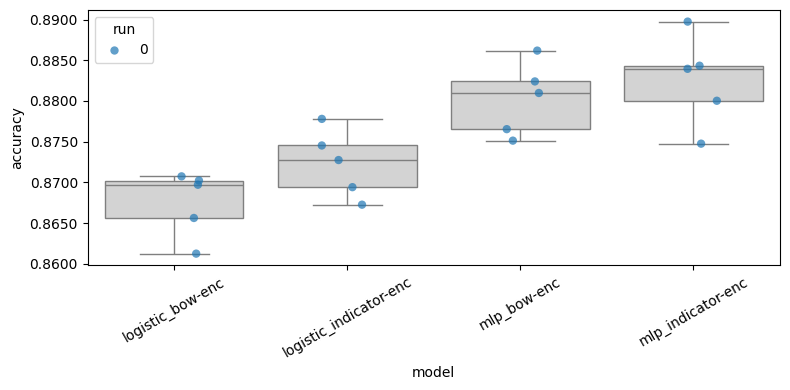

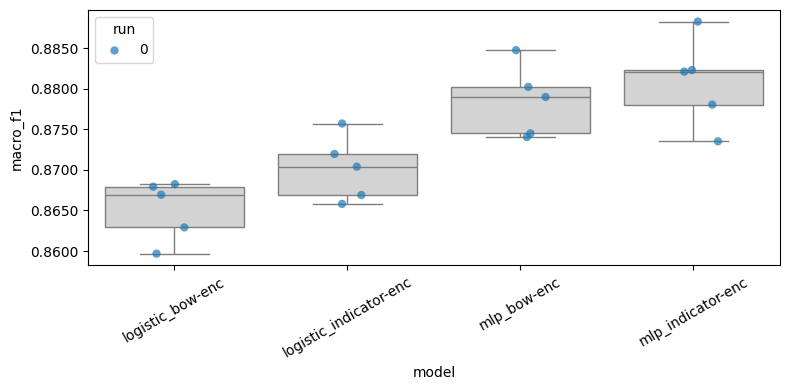

In [16]:
analysis.plot_box_and_points(metrics_df, metric='accuracy')
analysis.plot_box_and_points(metrics_df, metric='macro_f1')

### Observations from the summary table

- **Model effect:** the MLP scores about 1-1.5 percentage points higher than the log-linear model, for both encoders. This gap is clearly larger than the fold-to-fold variation in accuracy, so it looks real (to be confirmed by the Bayesian analysis).
- **Encoder effect:** token indicators score slightly higher than bag of words, but the gap is small. 
- **Metric robustness:** macro F1 ranks the systems in the same order as accuracy, so the conclusions do not depend on the metric.
- **Possible explanation:** most texts are short, so token counts are mostly 0 or 1.
- **Caveat:** with only 5 folds per system, the fold-to-fold variation is itself noisy, so small differences between systems should not be over-interpreted.

## Bayesian analysis

We compare systems pairwise with the Bayesian correlated t-test, which
accounts for the fact that cross-validation folds share training data and are therefore
not independent. For a pair (A, B), it gives a posterior distribution over the mean
difference in performance (B minus A). The **ROPE** (region of practical equivalence) is
the interval around zero inside which a difference is too small to matter in practice.
From the posterior we read three probabilities: A better (difference below the ROPE),
practically equivalent (inside the ROPE), and B better (above the ROPE).

**Choice of ROPE: 0.005 (half a percentage point of accuracy).**
- A difference below half a point would not change which system we would deploy.
- It is about the size of the fold accuracy std of our systems, so differences smaller
  than the noise level count as equivalent.

**Comparisons.** Each pair changes exactly one factor:
- *Encoder effect* (model fixed): indicator vs bag of words, for log-linear and for MLP.
- *Model effect* (encoder fixed): log-linear vs MLP, for each encoder.

In [17]:
ROPE = 0.005

def get_measurements(metric, sys_name):
    """Per-fold values of a metric for one system, flattened over runs."""
    return metrics_df[metrics_df.model == sys_name][metric].to_numpy()

def compare(a_name, b_name, metric="accuracy", rope=ROPE, plot=True):
    a = get_measurements(metric, a_name)
    b = get_measurements(metric, b_name)
    post = analysis.BenavoliCorrelatedT(a, b, names=[a_name, b_name])
    p_a, p_tie, p_b = post.probs(rope)
    print(f"[{metric}, ROPE={rope}] A={a_name}  B={b_name}\n"
          f"  mean diff (B-A)={post.mean_diff:+.4f}  "
          f"P(A better)={p_a:.3f}  P(tie)={p_tie:.3f}  P(B better)={p_b:.3f}  "
          f"effect size={post.effect_size:.2f}")
    if plot:
        _ = post.plot(rope)
    return {"A": a_name, "B": b_name, "metric": metric, "rope": rope,
            "mean_diff": post.mean_diff,
            "P(A better)": p_a, "P(tie)": p_tie, "P(B better)": p_b}

comparisons = [
    # encoder effect (model fixed)
    ('logistic_indicator-enc', 'logistic_bow-enc'),
    ('mlp_indicator-enc',      'mlp_bow-enc'),
    # model effect (encoder fixed)
    ('logistic_indicator-enc', 'mlp_indicator-enc'),
    ('logistic_bow-enc',       'mlp_bow-enc'),
]

### Posterior plots (accuracy)
Each plot shows the posterior of the mean difference (B minus A), the ROPE (shaded) and
the probability mass in each of the three regions.

[accuracy, ROPE=0.005] A=logistic_indicator-enc  B=logistic_bow-enc
  mean diff (B-A)=-0.0048  P(A better)=0.458  P(tie)=0.541  P(B better)=0.001  effect size=-3.40
[accuracy, ROPE=0.005] A=mlp_indicator-enc  B=mlp_bow-enc
  mean diff (B-A)=-0.0023  P(A better)=0.036  P(tie)=0.963  P(B better)=0.001  effect size=-2.11
[accuracy, ROPE=0.005] A=logistic_indicator-enc  B=mlp_indicator-enc
  mean diff (B-A)=+0.0102  P(A better)=0.000  P(tie)=0.005  P(B better)=0.995  effect size=8.89
[accuracy, ROPE=0.005] A=logistic_bow-enc  B=mlp_bow-enc
  mean diff (B-A)=+0.0127  P(A better)=0.000  P(tie)=0.004  P(B better)=0.996  effect size=8.24


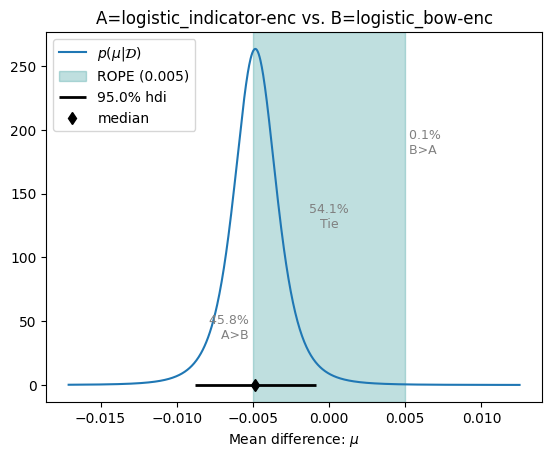

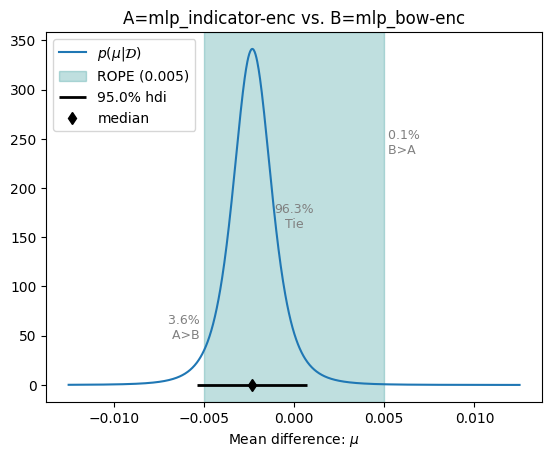

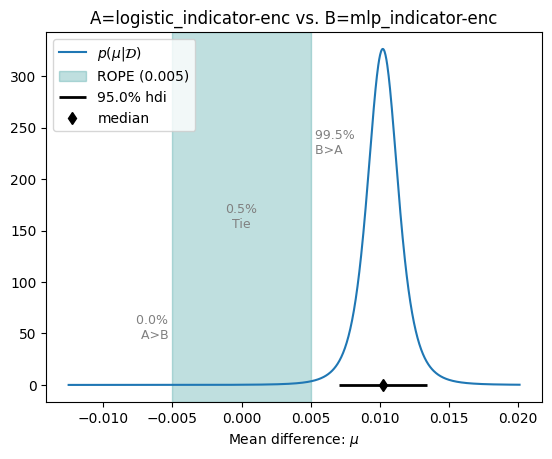

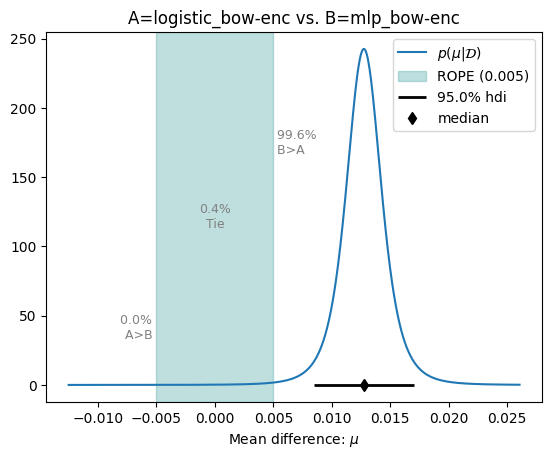

In [18]:
acc_results = [compare(a, b, metric="accuracy") for a, b in comparisons]